In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
np.set_printoptions(precision=2,suppress=True)

#####
<font color="#2c3e50" size="6"><div style="
    font-family: sans-serif;
    font-size: 1.2em;
    font-weight: 700;
    line-height: 1.2;
    background-color: #d9e6f2;
    border-radius: 8px;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    padding: 0.5em 1em;
    margin-top: 1em;
    margin-bottom: 0.6em;
    box-shadow: 0 2px 6px rgba(0,0,0,0.1);
" align="center">
3.1 Eigenvectors and Eigenvalues
</div></font>

The concepts of eigenvectors and eigenvalues are among the most important ideas in linear algebra, with a far-reaching applications in data science, differential equations, computer graphics, physics, and many other fields. Consider a linear transformation $T({\bf x})=A{\bf x}$, where $A$ is a square matrix. We can think of $T$ as a transformation that moves vector $\bf x$ to its image $T({\bf x})$. Normally, the image of $\bf x$ may point in a different direction and may have a different magnitude. However, there is a special class of vectors whose directions do not change under the transformation. This means that for such a vector $\bf v$ there is a scalar $\lambda$ such that $$T({\bf v})=A{\bf v}=\lambda{\bf v}$$

---
**<font color="red">Example 1</font>**

Let $A=\begin{bmatrix} 1 & 3 \\ 3 & 1 \end{bmatrix}$, ${\bf v}_1=\begin{bmatrix} 1 \\ 1\end{bmatrix}$ and  ${\bf v}_2=\begin{bmatrix} -1 \\ 2\end{bmatrix}$. Find the images of ${\bf v}_1$ and ${\bf v}_2$ under $T({\bf x})=A{\bf x}$ and determine whether their directions change.

**Solution**

Here is a figure showing both vectors and their images. We can see that ${\bf v}_1$ does not change its direction under $T$, but ${\bf v}_2$ does. 

<center> <img src="data:image/png;base64,  ...
 " width="30%"> </center>

Let's now compute the images to see that:

$$A{\bf v}_1=\begin{bmatrix} 1 & 3 \\ 3 & 1 \end{bmatrix}\begin{bmatrix} 1 \\ 1\end{bmatrix}=\begin{bmatrix} 4 \\ 4\end{bmatrix} = 4\begin{bmatrix} 1 \\ 1\end{bmatrix}=4{\bf v}_1$$

$$A{\bf v}_2=\begin{bmatrix} 1 & 3 \\ 3 & 1 \end{bmatrix}\begin{bmatrix} -1 \\ 2 \end{bmatrix}=\begin{bmatrix} 5 \\ -1 \end{bmatrix} \neq \lambda \begin{bmatrix} -1 \\ 2\end{bmatrix}$$

Indeed, $T$ stretches  ${\bf v}_1$ while preserving its direction, but changes the direction of ${\bf v}_2$.

---

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition</strong><br> An <strong>eigenvector</strong> of an $n \times n$ matrix $A$ is a nonzero vector $\bf v$ such that $A{\bf v}=\lambda{\bf v}$ for some scalar $\lambda$. The scalar $\lambda$ is called an <strong>eigenvalue</strong> of $A$ and $\bf v$ is called an <strong>eigenvector corresponding to $\lambda$</strong>
</div>

In Example 1, ${\bf v}_1$ is an eigenvector corresponding to an eigenvalue $\lambda=4$ since $A{\bf v}_1=4{\bf v}_1$. Moreover, we can see that it is quite easy to find the eigenvalue if we already know an eigenvector corresponding to it. However, usually we need to do the opposite: finding eigenvectors corresponding to a given eigenvalue.

Suppose we know that $\lambda$ is an eigenvalue of $A$, then we want to find all vectors ${\bf x}$ such that $A{\bf x}=\lambda{\bf x}$. We can rewrite this as follows:
$$A{\bf x}-\lambda{\bf x}={\bf 0}$$
$$A{\bf x}-\lambda I{\bf x}={\bf 0}$$
$$(A-\lambda I){\bf x}={\bf 0}$$

Therefore, all non-trivial solutions of $(A-\lambda I){\bf x}={\bf 0}$ must be eigenvectors of $A$ corresponding to $\lambda$

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #dd8452;
    background-color: rgba(250,100,60,0.16);
    margin: 0.4em 0;
">
<strong>⚠️Caution:</strong> Eigenvectors must be nonzero vectors, so only nontrivial solutions are valid.
</div>



**<font color="red">Example 2</font>**

$A=\begin{bmatrix} 1 & 3 \\ 3 & 1 \end{bmatrix}$. Show that $\lambda=-2$ is an eigenvalue of $A$ and find all eigenvectors corresponding to $\lambda=-2$

**Solution**

$$A-\lambda I = \begin{bmatrix} 1 & 3 \\ 3 & 1 \end{bmatrix}-(-2)\begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}=\begin{bmatrix} 1 & 3 \\ 3 & 1 \end{bmatrix}+\begin{bmatrix} 2 & 0 \\ 0 & 2 \end{bmatrix}=\begin{bmatrix} 3 & 3 \\ 3 & 3 \end{bmatrix}$$

Since columns of $A-\lambda I$ are linearly dependent, homogeneous equation $(A-\lambda I){\bf x}={\bf 0}$ has non-trivial solution. Hence, $\lambda=-2$ is an eigenvalue of $A$. To find the eigenvectors we solve this equation.

$$\begin{bmatrix} 3 & 3 & 0\\ 3 & 3 & 0\end{bmatrix} \sim \cdots \sim \begin{bmatrix} 1 & 1 & 0\\ 0 & 0 & 0\end{bmatrix}$$

The solution is of the form $${\bf x}=t\begin{bmatrix} -1 \\ 1 \end{bmatrix}$$

Therefore, every nonzero vector of this form is an eigenvector corresponding for $\lambda=-2$.

---

If $\lambda$ is an eigenvalue, then the null space $Nul(A-\lambda I)$ consists of the zero vector and all eigenvectors corresponding to $\lambda$. This subspace is called an **eigenspace**  of $A$ corresponding to $\lambda$. 

From the Examples 1 and 2, we see that $A$ has two eigenvalues $\lambda = 4$ and $\lambda=-2$. The eigenspace corresponding to $\lambda=-2$ is the span of the vector $\begin{bmatrix} -1 \\ 1 \end{bmatrix}$. It can be shown that the eigenspace corresponding to $\lambda=4$ is the span of the vector $\begin{bmatrix} 1 \\ 1 \end{bmatrix}$. There are no other eigenvalues. The next theorem shows why not. 

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> The proof for this theorem highlights one of the important uses of eigenvectors: being able to rewrite matrix-vector multiplication as scalar-vector multiplication.
</div>

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong><br> Let ${\bf v}_1, \cdots, {\bf v}_k$ be eigenvectors of an $n \times n$ matrix $A$, corresponding to distinct eigenvalues $\lambda_1, \cdots, \lambda_k$. Then ${\bf v}_1, \cdots, {\bf v}_k$ are linearly independent.
</div>

**Proof**

We will prove this theorem by contradiction. We assume that ${\bf v}_1, \cdots, {\bf v}_k$ are linearly dependent and show that this leads to a contradiction.

Suppose ${\bf v}_1, \cdots, {\bf v}_k$ are linearly dependent, then there exists an index $m < k$ such that we can rewrite ${\bf v}_{m+1}$ as a linear combination of **linearly independent** vectors before it.  $${\bf v}_{m+1}=c_1{\bf v}_{1}+c_2{\bf v}_{2}+ \cdots +c_{m}{\bf v}_{m}$$

We multiply both sides of the equation by $A$:
   $$A{\bf v}_{m+1}=A(c_1{\bf v}_{1}+c_2{\bf v}_{2}+ \cdots +c_{m}{\bf v}_{m})$$
   $$A{\bf v}_{m+1}=c_1A{\bf v}_{1}+c_2A{\bf v}_{2}+ \cdots +c_{m}A{\bf v}_{m}$$
Now we use the fact that $A{\bf v}_i=\lambda_i{\bf v}_i$:
   $$\lambda_{m+1}{\bf v}_{m+1}=c_1\lambda_{1}{\bf v}_{1}+c_2\lambda_{2}{\bf v}_{2}+ \cdots +c_{m}\lambda_{m}{\bf v}_{m}$$
   
Next, we multiply original equation by $\lambda_{m+1}$:
   $$\lambda_{m+1}{\bf v}_{m+1}=c_1\lambda_{m+1}{\bf v}_{1}+c_2\lambda_{m+1}{\bf v}_{2}+ \cdots +c_{m}\lambda_{m+1}{\bf v}_{m}$$


Next, we subtract one equation from the other. The left-hand sides are identical and therefore cancel. On the right-hand side, we can group terms that differ only in their eigenvalues:

$$0=c_1(\lambda_{1}-\lambda_{m+1}){\bf v}_{1}+c_2(\lambda_{2}-\lambda_{m+1}){\bf v}_{2}+ \cdots +c_{m}(\lambda_{m}-\lambda_{m+1}){\bf v}_{m}$$

Since $ {\bf v}_{1}, \cdots {\bf v}_{m}$ are linearly independent, all coefficients must be zero:

$$c_1(\lambda_{1}-\lambda_{m+1}) = \cdots =c_m(\lambda_{m}-\lambda_{m+1})=0$$

Since all eigenvalues are distinct, their differeces cannot be zero. Therefore,

$$c_1= \cdots = c_m=0$$
And so,

$${\bf v}_{m+1}=0{\bf v}_{1}+0{\bf v}_{2}+ \cdots +0{\bf v}_{m}={\bf 0}$$

This is impossible since all eigenvectors must be nonzero.

Since we have reached a contradiction, our assumption was false. Therefore, ${\bf v}_1, \cdots, {\bf v}_k$ are linearly independent.

---

By this theorem, we can see that if $A$ in the Examples 1 and 2 had a third eigenvalue, then three eigenvectors corresponding to three different eigenvalues must be linearly independent. However, since $A$ is a $2 \times 2$ matrix, its eigenvectors are in $\mathbb{R}^2$ and it is impossible to have three linearly independent vectors in $\mathbb{R}^2$.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Characteristic Polynomial</b>
</div></font> 

At this point, we know how to find eigenvectors once the eigenvalues are known. What we still need is a method for finding eigenvalues without already knowing the eigenvectors. To do this we consider the matrix $A-\lambda I$. The value $\lambda$ is an eigenvalue if and only if $A-\lambda I$ is singular. Since a matrix is singular precisely when its determinant is zero, we obtain the following theorem.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong><br> A scalar $\lambda$ is an eigenvalue of an $n\times n$ matrix $A$ if and only if $det(A-\lambda I)=0$
</div>



The equation $det(A-\lambda I)=0$ is called the **characteristic equation** of $A$ and the polynomial $det(A-\lambda I)$ is called the **characteristic polynomial** of $A$. If $A$ is an $n\times n$ matrix, then $det(A-\lambda I)$ is a polynomial of degree $n$. Therefore, it has at most $n$ distinct solutions, and hence $A$ has at most $n$ distinct eigenvalues. 



---
**<font color="red">Example 3</font>**

Find the characteristic equation and eigenvalues of $A=\begin{bmatrix} 1 & 3 \\ 3 & 1 \end{bmatrix}$

**Solution**


$$A-\lambda I= \begin{bmatrix} 1 & 3 \\ 3 & 1 \end{bmatrix} - \begin{bmatrix} \lambda & 0 \\ 0 & \lambda \end{bmatrix}= \begin{bmatrix} 1-\lambda & 3 \\ 3 & 1-\lambda \end{bmatrix}$$

Then the characteristic equation is 
$$det(A-\lambda I)=\begin{vmatrix} 1-\lambda & 3 \\ 3 & 1-\lambda \end{vmatrix} = (1-\lambda)(1-\lambda)-9=\lambda^2-2\lambda-8=(\lambda-4)(\lambda+2)=0$$

We have two solutions, $\lambda=-2$ and $\lambda=4$.

This is another way to see that $A$ cannot have a third eigenvalue. 

---

Since, eigenvalues are the roots of the characteristic polynomial, we can use the concept of root multiplicity to describe eigenvalues. The number of times an eigenvalue appears as a root of the characteristic polynomial is called its **algebraic multiplicity**. For instance, in Example 3, we have two eigenvalues both with multiplicity of $1$.


---
**<font color="red">Example 4</font>**

Find the eigenvalues of $A=\begin{bmatrix} 2 & 2 & 1 \\ 1 & 3 & 1 \\ 1 & 2 & 2\end{bmatrix}$ and their algebraic multiplicity. Then find a basis for each eigenspace.

**Solution**

The characteristic equation is
$$det(A-\lambda I)=\begin{vmatrix} 2-\lambda & 2 & 1 \\ 1 & 3-\lambda & 1 \\ 1 & 2 & 2-\lambda\end{vmatrix}$$
$$=(2-\lambda)(3-\lambda)(2-\lambda)+2+2-(3-\lambda)-2(2-\lambda)-2(2-\lambda)$$
$$=-\lambda^3+7\lambda^2-11\lambda+5=0$$

This time, we have a cubic polynomial, which is more difficult to solve. Hint: You can use the Rational Zeros Theorem from Pre-Calculus to find its roots. 

Here is its factorization:

$$ -(\lambda-5)(\lambda-1)^2=0$$

So, we have two eigenvalues: $\lambda=5$ with multiplicity $1$ and $\lambda=1$ with multiplicity $2$.

Next, we find bases for each eigenspace. 

**1.** Basis for the eigenspace corresponding to $\lambda=1$

$$A-1I=\begin{bmatrix} 2-1 & 2 & 1 \\ 1 & 3-1 & 1 \\ 1 & 2 & 2-1\end{bmatrix}=\begin{bmatrix} 1 & 2 & 1 \\ 1 & 2 & 1 \\ 1 & 2 & 1\end{bmatrix}\sim \cdots \sim \begin{bmatrix} 1 & 2 & 1 \\ 0 & 0 & 0 \\ 0 & 0 & 0\end{bmatrix}$$

The general solution to the homogeneous equation $(A-1I){\bf x}={\bf 0}$ is $${\bf x}=x_2\begin{bmatrix}-2 \\ 1 \\ 0 \end{bmatrix}+x_3\begin{bmatrix} -1 \\ 0 \\ 1 \end{bmatrix}$$

Therefore, a basis for the eigenspace corresponding to $\lambda=1$ is $$\left\{\begin{bmatrix}-2 \\ 1 \\ 0 \end{bmatrix}, \begin{bmatrix} -1 \\ 0 \\ 1 \end{bmatrix}\right\}$$

**2.** Basis for the eigenspace corresponding to $\lambda=5$

$$A-5I=\begin{bmatrix} 2-5 & 2 & 1 \\ 1 & 3-5 & 1 \\ 1 & 2 & 2-5\end{bmatrix}=\begin{bmatrix} -3 & 2 & 1 \\ 1 & -2 & 1 \\ 1 & 2 & -3\end{bmatrix}\sim \cdots \sim \begin{bmatrix} 1 & 0 & -1 \\ 0 & 1 & -1 \\ 0 & 0 & 0\end{bmatrix}$$


The general solution to the homogeneous equation $(A-5I){\bf x}={\bf 0}$ is $${\bf x}=x_3\begin{bmatrix} 1 \\ 1 \\ 1 \end{bmatrix}$$

Therefore, a basis for the eigenspace corresponding to $\lambda=5$ consists of just one vector: $$\left\{\begin{bmatrix} 1 \\ 1 \\ 1 \end{bmatrix}\right\}$$

---

In practice, finding eigenvalues of large matrices is incredibly difficult, except for a few special cases. Computing determinants with symbolic variables becomes cumbersome, and solving high-degree polynomial equations can be extremely hard. In practice, eigenvalues of large matrices are almost always found numerically using computers. Before learning computational methods, let us look at some important special cases where eigenvalues are easy to determine.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong><br> An $n \times n$ matrix $A$ is singular if and only if $0$ is an eigenvalue of $A$. 
</div>

This follows from the fact that $Nul(A-0 I) = Nul(A)$. A matrix is singular if and only if its null space contains nonzero vectors. Therefore, $A$ is singular if and only if $0$ is an eigenvalue of $A$.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong><br> The eigenvalues of a triangular matrix are the entries on the main diagonal.
</div>



**Proof**

If $A$ is triangular, then $A-\lambda I$ is also triangular. The determinant of the triangular matrix is equal to the product of entries on the main diagonal. Therefore,

$$det(A-\lambda I)=(a_{11}-\lambda)(a_{22}-\lambda)\cdots(a_{nn}-\lambda)=0$$


Hence, the eigenvalues are $\lambda=a_{11}, \lambda=a_{22},\cdots , \lambda=a_{nn}$, which are precisely the diagonal entries.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Eigenvectors with Python</b>
</div></font> 

To find eigenvalues and eigenvectors in Python, we can use either NumPy or SciPy. NumPy is simpler and sufficient for everything we will do here. SciPy offers additional functionality and more advanced methods. We will use NumPy in this chapter.

Let's consider the matrix from Example 4: $$A=\begin{bmatrix} 2 & 2 & 1 \\ 1 & 3 & 1 \\ 1 & 2 & 2\end{bmatrix}$$

First, let's find the eigenvalues of $A$:

In [2]:
A=np.array([[2,2,1],[1,3,1],[1,2,2]])
print( np.linalg.eigvals(A) )

[5. 1. 1.]


We can also get both eigenvalues and eigenvectors using `np.linalg.eig()`.

In [3]:
eigenvalues, eigenvectors = np.linalg.eig(A)
print(f'Eigenvalues \n {eigenvalues}')
print(f'Eigenvectors \n {eigenvectors}')

Eigenvalues 
 [5. 1. 1.]
Eigenvectors 
 [[-0.58  0.04  0.78]
 [-0.58 -0.46 -0.54]
 [-0.58  0.89  0.3 ]]


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong><br>  <span style="line-height: 1.5; display: inline-block;"><strong>1.</strong> Eigenvectors are stored as columns and in the same order as the corresponding eigenvalues. Therefore, the first column is an eigenvector corresponding to the first eigenvalue, which is $5$. <br></span>
<strong>2.</strong> All eigenvectors are normalized (have norm equal to $1$).
</div>


We can also find the characteristic polynomial of $A$ using `np.poly()`. It returns the polynomial coefficients in descending order of powers. Recall our polynomial was $-\lambda^3+7\lambda^2-11\lambda+5$. NumPy's `np.poly(A)` returns the coefficients of the equivalent polynomial $det(\lambda I-A)=\lambda^3-7\lambda^2+11\lambda-5$, which differs only by a factor of $-1$. However, both polynomials have the same roots.

In [4]:
print(np.poly(A))

[ 1. -7. 11. -5.]


We can display the polynomial itself using the `Polynomial()` class from the `numpy.polynomial` module. Note that we have to reverse the order of the coefficients because `Polynomial()` expects them in ascending order of powers.

In [5]:
Polynomial(np.poly(A)[::-1])

Polynomial([-5., 11., -7.,  1.], domain=[-1.,  1.], window=[-1.,  1.], symbol='x')

Finally, let's plot it

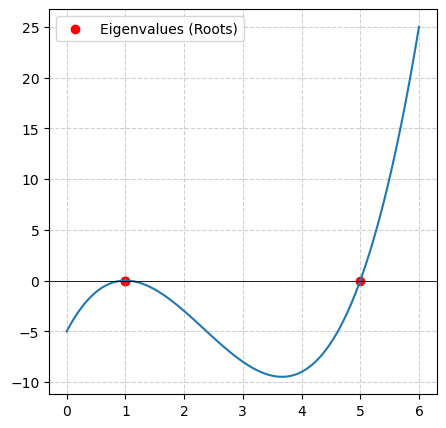

In [6]:
P = Polynomial(np.poly(A)[::-1])
x = np.linspace(0, 6, 100)

plt.subplots(figsize=(5,5))
plt.plot(x, P(x))

EigVal=np.linalg.eigvals(A)
Zeros=np.zeros_like(np.linalg.eigvals(A))
plt.scatter(EigVal, Zeros, color='red', label='Eigenvalues (Roots)')

plt.axhline(y=0, color='black', lw=0.6) 
plt.grid(alpha=0.6,which='major', axis='both',linestyle='--')
plt.legend()
plt.show()

---
**<font color="red">Example 5</font>**

Let $A=\begin{bmatrix}  1 & 1 \\ 0.5 & 1.5 \end{bmatrix}$. Plot $100$ equally spaced unit vectors in ${\mathbb{R}^2}$ in blue color (i.e. points on the unit circle). In red, plot the images of these points under the transformation ${\bf x} \rightarrow A{\bf x}$. Finally, draw the two eigenspaces of $A$ in green.

**Solution**

In [7]:
A=np.array([[1,1],[0.5,1.5]])
eigenvalues, eigenvectors = np.linalg.eig(A)
print(f'Eigenvalues \n {eigenvalues}')
print(f'Eigenvectors \n {eigenvectors}')

Eigenvalues 
 [0.5 2. ]
Eigenvectors 
 [[-0.89 -0.71]
 [ 0.45 -0.71]]


We can see we have two eigenvalues: $0.5$ and $2$. So, we should see stretch along one of the eigen-directions and contraction along the other eigen-direction.

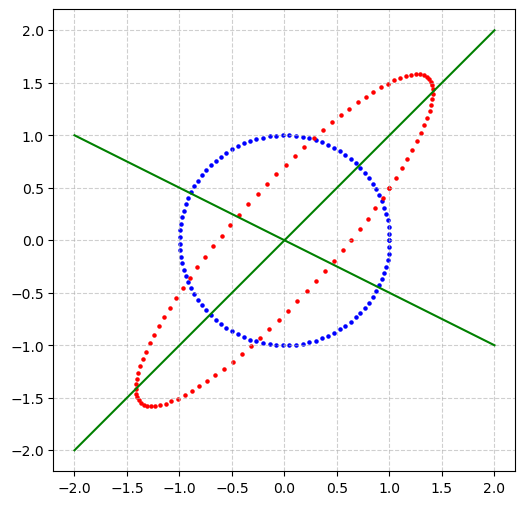

In [9]:
fig, ax = plt.subplots(figsize = (6, 6))
ax.set_aspect(1)

# unit circle (blue)
t = np.linspace(0, 2*np.pi, 100)
x=np.cos(t)
y=np.sin(t)
plt.scatter(x,y, s=5, color='b')

#images (red)
vec=np.array([x,y])
imag=A@vec
plt.scatter(imag[0],imag[1], s=5, color='r')

#lines (eigenspaces) (green)
lx=np.linspace(-2,2,100)
ly1=lx*eigenvectors[1][0]/eigenvectors[0][0]
ly2=lx*eigenvectors[1][1]/eigenvectors[0][1]
plt.plot(lx,ly1,'-g')  
plt.plot(lx,ly2,'-g')

plt.grid(alpha=0.6,which='major', axis='both',linestyle='--')
plt.show()

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Eigenvectors and Leontief Input-Output Model</b>
</div></font> 

Let's see how eigenvectors can be applied in a topic we studied earlier: the closed Leontief input-output model.

First, let's briefly review this model.

The closed Leontief input-output model describes an economic system consisting of several sectors, where each sector requires outputs of other sectors and there is no external demand. All production in the system is consumed within the system itself. The goal is to find an equilibrium of the model; that is, production levels that balance the entire economy so that every sector receives exactly the inputs it needs, with no shortages and no overproduction. 

We measure the total output of each sector by its monetary value and represent these values using a vector $\bf p$, called the production vector. We also define a consumption matrix $C$ that contains all input-output ratios. If $\bf p$ is the production vector, then $C{\bf p}$ represents the total output consumed by each sector. At equilibrium, total production must equal total internal consumption: $$C{\bf p}={\bf p}$$ This means that ${\bf p}$ is an eigenvector of $C$ corresponding to the eigenvalue of $1$.

Keeping this in mind, let's solve Example 3 from Chapter 1.8 ("Application") again. We will use Python to speed up calculations as well.

---
**<font color="red">Example 6</font>**

Suppose our economy has three sectors: Transportation, Manufacturing and Energy. Each sector produces its corresponding product, and each sector consumes products from all sectors. The diagram and the table below show how the products are distributed.

<center> <img src="data:image/png;base64,  ...
 " width="80%"> </center>

**Solution**

Construct consumption matrix $C$ and find eigenvalues and eigenvectors:

In [10]:
C=np.array([[0.3, 0.4, 0.3],[0.5, 0.2, 0.5],[0.2, 0.4, 0.2]])
eigenvalues, eigenvectors = np.linalg.eig(C)
print(f'Eigenvalues \n {eigenvalues}')
print(f'Eigenvectors \n {eigenvectors}')

Eigenvalues 
 [ 1.   0.  -0.3]
Eigenvectors 
 [[-0.58 -0.71  0.27]
 [-0.66  0.   -0.8 ]
 [-0.48  0.71  0.53]]


We can see that we have an eigenvalue of $1$ in the first position, and therefore, the first vector is the eigenvector we need:

In [11]:
v=eigenvectors[:,0]
print(v)

[-0.58 -0.66 -0.48]


Any vector in the eigenspace of $1$ is an equilibrium vector. As we did in the "Application" chapter, if we want the third value to be $100$, we can rescale the basis vector $\bf v$:

In [12]:
print(v*100/v[2])

[122.22 138.89 100.  ]


---

In fact, the proof that the closed Leontief input-output model always has an equilibrium solution reveals an important property of the consumption matrix: it must have an eigenvalue equal to $1$. Observe that the entries in each column of the consumption matrix $C$ sum up to $1$. Therefore, the rows of $C^T$ also add up to $1$. Then,

$$C^T\begin{bmatrix} 1 \\ 1 \\ \vdots \\ 1\end{bmatrix}=\begin{bmatrix} 1 \\ 1 \\ \vdots \\ 1\end{bmatrix}$$

This shows that the vector of all ones is an eigenvector of $C^T$ corresponding to the eigenvalue $1$.

Finally, since a matrix and its transpose have the same characteristic polynomial $$det(C-\lambda I)=det ((C-\lambda I)^T)= det(C^T-\lambda I),$$ matrices $C$ and $C^T$ have the same eigenvalues. Hence, $C$ also has eigenvalue $1$.

######
<font color="#0fbf0f" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Exercises</b>
</div></font> 

**1.** 
>Let $A=\begin{bmatrix} 1& 1 & 0  \\ 1 & 0 & 1  \\ 0 & 1 & 1   \end{bmatrix}$. Check whether ${\bf x}$ is an eigenvector of $A$. If so, find its corresponding eigenvalue.<br><br>
>***a.*** ${\bf x}=\begin{bmatrix} 1 \\ 1\\ 1 \end{bmatrix}; \quad \quad$
>***b.*** ${\bf x}=\begin{bmatrix} 1 \\ 1\\ 0 \end{bmatrix}; \quad \quad$
>***c.*** ${\bf x}=\begin{bmatrix} 1 \\ -2\\ 1 \end{bmatrix}$ <br>

**2.**
> For each of the following matrices, find its characteristic polynomial. You do not need to find the eigenvalues. <br><br>
> ***a.*** $\begin{bmatrix} 1 & 3  & -1 \\ 0 & 3 & -2  \\ 0 & -2& -1 \end{bmatrix}; \quad \quad$
>***b.*** $\begin{bmatrix} 1 & 1  & 2 \\ 0 & -1 & -2  \\ 1 & 2& -1 \end{bmatrix}$

**3.**
> For each of the following matrices, find its characteristic polynomial, eigenvalues, and a basis for each eigenspace. <br><br>
> ***a.*** $\begin{bmatrix} 1 & 3   \\ 0 & 3 \end{bmatrix}; \quad \quad\quad \quad\quad $
>***b.*** $\begin{bmatrix} 1 & 1 \\ 3& -1 \end{bmatrix};$ <br><br>
> ***c.*** $\begin{bmatrix} 1 & 0 & -2 \\ 0 & 0 & 0   \\-2&0 & 4 \end{bmatrix}; \quad \quad$
>***d.*** $\begin{bmatrix} 4 & 0& -1 \\ 0 & 3& 0 \\ 1& 0 & 2 \end{bmatrix}$ <br>

**4.**
>Repeat Exercise 3 using Python.

**5.**
> Based on geometric description of each linear transformation in $\mathbb{R}^2$, find the eigenvalues and eigenspaces of its standard matrix. <br><br>
> ***a.*** Reflection across the $x_1$-axis. <br>
> ***b.*** Orthogonal projection onto the $x_2$-axis. <br>
> ***c.*** Rotation about the origin by $30$ degrees clockwise. <br>
> ***d.*** Rotation about the origin by $180$ degrees clockwise. <br>
> ***e.*** Horizontal stretch along the $x_1$-axis by a factor of $2$. <br>

**6.** 
> Suppose $p(\lambda)=\lambda^2(\lambda-1)^3(\lambda-3)^4$ is a characteristic polynomial of the matrix $A$.<br><br>
> ***a.*** What is the size of the matrix $A$?<br>
> ***b.*** Is $A$ invertible?<br>
> ***c.*** How many distinct eigenspaces does $A$ have?

**7.**
> Suppose $A$ is an invertible matrix with an eigenvalue $\lambda$. Show that $A^{-1}$ has an eigenvalue $\frac{1}{\lambda}$.

**8.**
> Suppose ${\bf v}$ is an eigenvector of $A$ corresponding to an eigenvalue $\lambda$. What is $A^k{\bf v}$?

**9.**
> Suppose ${\bf v}_1$ and ${\bf v}_2$ are eigenvectors of a $2 \times 2$ matrix $A$, with eigenvalues $1$ and $0.5$. Let $\bf x$ be a vector in $\mathbb{R}^2$. <br><br>
> ***a.*** Explain why $\bf x$ can be expressed as a linear combination of ${\bf v}_1$ and ${\bf v}_2$. <br>
> ***b.*** Suppose ${\bf x} = 2{\bf v}_1-3{\bf v}_2 $. Express $A {\bf x}$, $A^2 {\bf x}$ and $A^k {\bf x}$ in terms of ${\bf v}_1$ and ${\bf v}_2$.<br>
> ***c.*** As $k \rightarrow \infty$, what does $A^k {\bf x}$ approach? 
